# 02. Target Analysis & Behavioral Distribution

**Project:** Sasol Loyalty Customer Value & Opportunity Prediction

### Objectives:
1. Inspect ground-truth validation targets generated for cutoff `2025-09-01`.
2. Characterize distributions of `CLV_fuel` and `CLV_nonfuel` (zero-inflation & log scaling).
3. Analyze class distribution and class imbalance across the 17 authoritative `Opportunity` labels.
4. Investigate joint relationships between continuous spend targets and categorical opportunity states.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sasol_customer_value import config
from sasol_customer_value.utils.helpers import set_seed

set_seed(config.RANDOM_SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

## 1. Load Generated Validation Labels (Cutoff: 2025-09-01)

In [2]:
val_labels_path = config.PROCESSED_DATA_DIR / "val_labels_20250901.parquet"
df_val = pd.read_parquet(val_labels_path)
print(f"Loaded {len(df_val):,} validation customer targets")
df_val.head(10)

Loaded 5,238 validation customer targets


,ID,CLV_fuel,CLV_nonfuel,Opportunity
0,4001000000001,0.000000,0.000000,Inactivity
1,4001000000003,1.905370,0.000000,Stable
2,4001000000004,2.486012,2.894988,Existing-category growth: Fuel
3,4001000000006,2.813919,2.627617,Existing-category growth: Other
4,4001000000007,0.000000,0.000000,Inactivity
5,4001000000008,2.159413,2.042279,Existing-category growth: Fuel
6,4001000000009,2.028792,0.000000,Stable
7,4001000000010,1.354267,0.000000,Existing-category growth: Fuel
8,4001000000011,1.743920,0.000000,Stable
9,4001000000012,2.071931,0.000000,Existing-category growth: Fuel


## 2. Regression Targets: Distribution & Zero-Inflation Analysis

Zero-inflation in CLV_fuel:    29.25%
Zero-inflation in CLV_nonfuel: 65.06%
Zero-inflation in both targets:27.42%


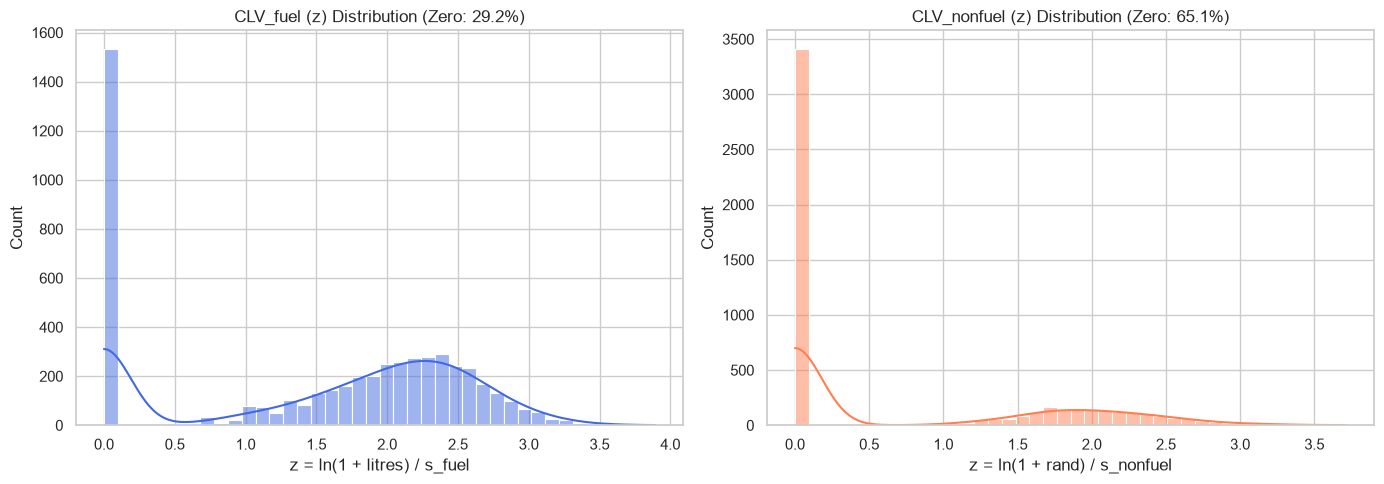

In [3]:
fuel_zero = (df_val["CLV_fuel"] == 0).mean() * 100
nonfuel_zero = (df_val["CLV_nonfuel"] == 0).mean() * 100
both_zero = ((df_val["CLV_fuel"] == 0) & (df_val["CLV_nonfuel"] == 0)).mean() * 100

print(f"Zero-inflation in CLV_fuel:    {fuel_zero:.2f}%")
print(f"Zero-inflation in CLV_nonfuel: {nonfuel_zero:.2f}%")
print(f"Zero-inflation in both targets:{both_zero:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_val["CLV_fuel"], kde=True, bins=40, ax=axes[0], color="royalblue")
axes[0].set_title(f"CLV_fuel (z) Distribution (Zero: {fuel_zero:.1f}%)")
axes[0].set_xlabel("z = ln(1 + litres) / s_fuel")

sns.histplot(df_val["CLV_nonfuel"], kde=True, bins=40, ax=axes[1], color="coral")
axes[1].set_title(f"CLV_nonfuel (z) Distribution (Zero: {nonfuel_zero:.1f}%)")
axes[1].set_xlabel("z = ln(1 + rand) / s_nonfuel")

plt.tight_layout()
plt.show()

## 3. Opportunity Target: Class Imbalance & Frequencies

The evaluation metric uses **Weighted F1 Score** across all 17 classes.

                                           Count  Percentage (%)
Opportunity                                                     
Inactivity                                  1436           27.42
Existing-category growth: Fuel              1435           27.40
Stable                                      1404           26.80
Existing-category growth: Other              278            5.31
Existing-category growth: Beverages          188            3.59
Existing-category growth: Food & beverage    129            2.46
New category adoption: Beverages              63            1.20
New category adoption: Lubricants             54            1.03
New category adoption: Other                  52            0.99
New category adoption: Food & beverage        50            0.95
New category adoption: Confectionary          27            0.52
New category adoption: Snacking               25            0.48
New category adoption: Ice-cream              23            0.44
New category adoption: To

C:\Users\amoge\AppData\Local\Temp\ipykernel_11820\1792524978.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=opp_counts.values, y=opp_counts.index, palette="viridis")


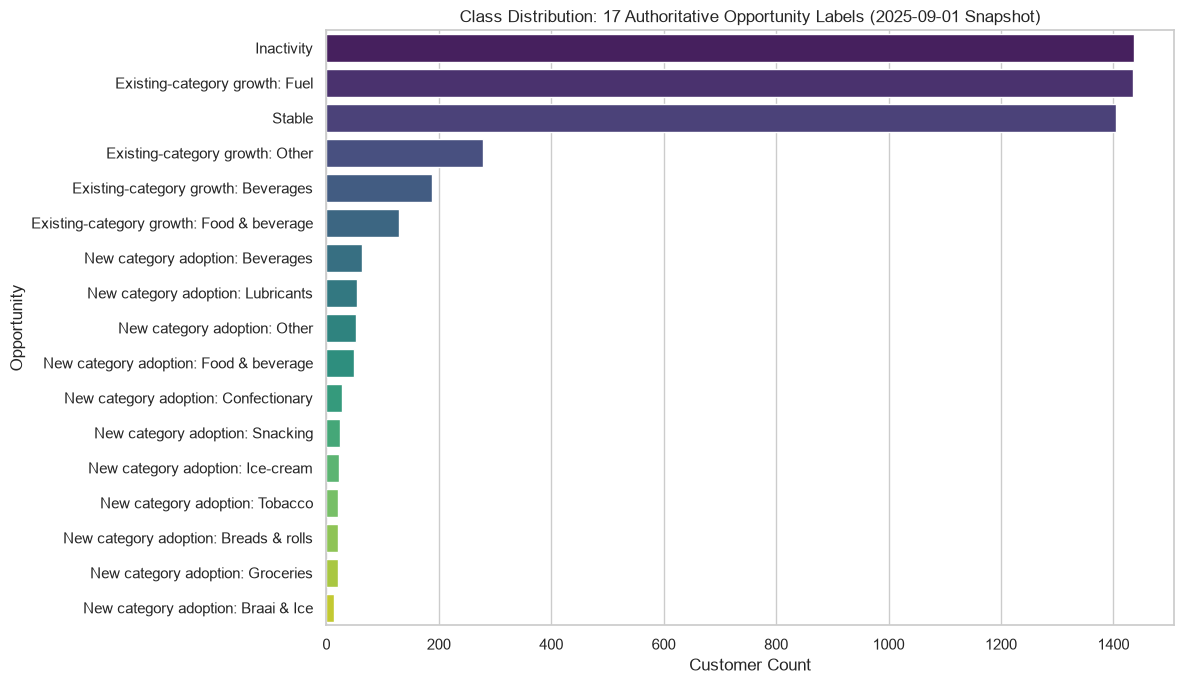

In [4]:
opp_counts = df_val["Opportunity"].value_counts()
opp_prop = (df_val["Opportunity"].value_counts(normalize=True) * 100).round(2)

summary_df = pd.DataFrame({"Count": opp_counts, "Percentage (%)": opp_prop})
print(summary_df)

plt.figure(figsize=(12, 7))
sns.barplot(x=opp_counts.values, y=opp_counts.index, palette="viridis")
plt.title("Class Distribution: 17 Authoritative Opportunity Labels (2025-09-01 Snapshot)")
plt.xlabel("Customer Count")
plt.tight_layout()
plt.show()

## 4. Cross-Target Coupling: Spend Conditional on Opportunity

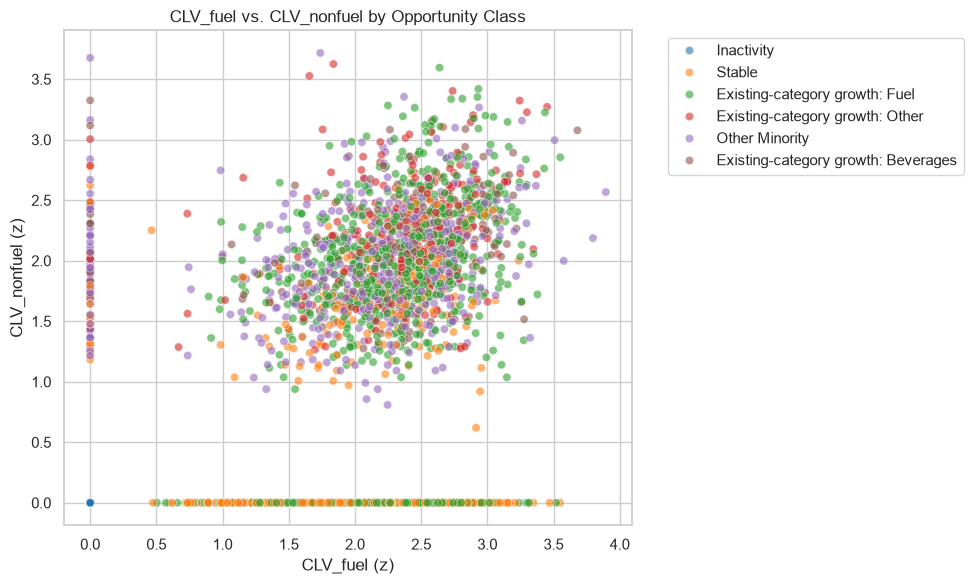

In [5]:
# Fuel vs Non-fuel scatter colored by Opportunity
top_classes = opp_counts.head(5).index.tolist()
df_val["TopOpportunity"] = df_val["Opportunity"].apply(lambda c: c if c in top_classes else "Other Minority")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_val,
    x="CLV_fuel",
    y="CLV_nonfuel",
    hue="TopOpportunity",
    alpha=0.6,
    palette="tab10"
)
plt.title("CLV_fuel vs. CLV_nonfuel by Opportunity Class")
plt.xlabel("CLV_fuel (z)")
plt.ylabel("CLV_nonfuel (z)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()